# Project 1: VaR and ES -- Estimation, Backtesting, and Model Comparison

**Names of all group members:**
- Firstname Lastname (email@example.com)
- Firstname Lastname (email@example.com)

---

## 0) Setup

Creates necessary folders, sets parameters, and fixes the random seed. Keep this seed fixed; the whole run must be reproducible from it.

In [1]:
# If a package import fails, install it in your environment, e.g.:
# %pip install arch statsmodels

import os
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
from pathlib import Path
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox



PROJECT_DIR = Path.cwd()
DATA_FILE = PROJECT_DIR / "QRM_2026_Project_prices.csv"   # provided with the project; do not re-download
OUT_DIR = PROJECT_DIR / "output"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Parameters
TICKERS = ["AAPL", "META", "JPM"]   # every question is run separately on each stock
WINDOW = 504                        # estimation window of every model, in trading days (Questions 2-5)
EVAL_START = 504                    # Questions 3-5: forecast days are all days after the first 504
REFIT = 21                          # Questions 4-5: re-estimate every this many trading days
ALPHAS = [0.975, 0.99]              # confidence levels used throughout Questions 2-5
DEEP_ALPHA = 0.999                  # Question 6: the extreme level EVT is asked for
M_SIM = 10_000                      # Questions 3(c), 4(d): Acerbi-Szekely simulated samples
LB_LAGS = 10                        # Ljung-Box H in Questions 1 and 4
NW_LAGS = 10                        # Newey-West truncation lag of the Diebold-Mariano test
SEED = 0                            # fix this, state it in the report, do not change it later

rng = np.random.default_rng(SEED)
print("Project dir:", PROJECT_DIR)


Project dir: /Users/victornouvelleere/Documents/MA3/QRM/Assignment_1


## 1) Data

The prices were downloaded once with `yfinance` (adjusted closes, 2 January 2013 to 30 June 2026,
downloaded on 28 October 2026) and are provided as `QRM_2026_Project_prices.csv`. Read this file;
do not download the data again, since Yahoo revises adjusted prices back in time.

In [2]:
price_df = pd.read_csv(DATA_FILE, index_col=0, parse_dates=True)[TICKERS]
print(price_df.shape, price_df.index[0].date(), "to", price_df.index[-1].date())   # (3393, 3)

(3393, 3) 2013-01-02 to 2026-06-30


## 2) Log-returns and losses

Construct $R_t=\log(P_t/P_{t-1})$ for each ticker. The log-loss used everywhere in this project is
$L_t=-R_t$. Every question is run separately on each of the three columns; there is no portfolio.

In [3]:
returns = np.log(price_df / price_df.shift(1)).dropna()
losses = -returns

print(returns.shape, returns.index[0].date(), "to", returns.index[-1].date())   # (3392, 3)
returns.head()

(3392, 3) 2013-01-03 to 2026-06-30


,AAPL,META,JPM
Date,,,
2013-01-03,-0.012703,-0.008248,-0.002017
2013-01-04,-0.028250,0.035029,0.017569
2013-01-07,-0.005900,0.022689,0.001101
2013-01-08,0.002688,-0.012312,0.001980
2013-01-09,-0.015752,0.051311,-0.000660


## Question 1 -- Stylized facts

For each stock: (a) plot the return series; (b) ACF of returns and of squared returns, and the
Ljung-Box test with $H$ = `LB_LAGS` on both (`statsmodels.stats.diagnostic.acorr_ljungbox`);
(c) QQ-plot and Jarque-Bera.

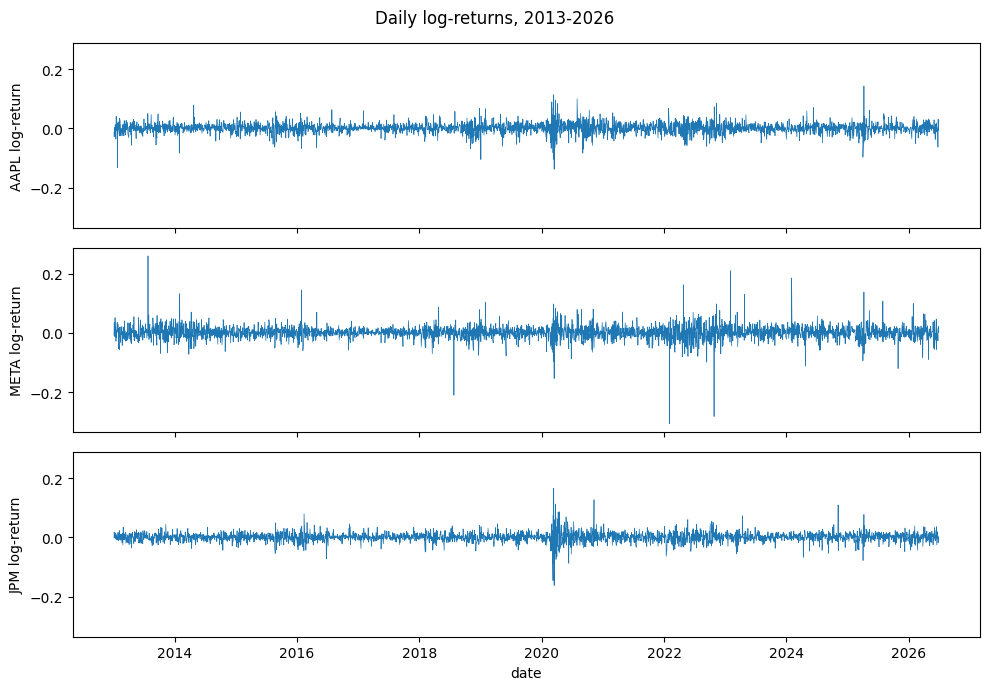

AAPL    1.78
META    2.41
JPM     1.63
dtype: float64
      AAPL  META   JPM
Date                  
2013  1.81  2.78  1.20
2014  1.36  2.23  1.13
2015  1.69  1.62  1.40
2016  1.47  1.75  1.55
2017  1.10  1.07  1.02
2018  1.81  2.47  1.40
2019  1.66  1.75  1.18
2020  2.94  2.90  3.42
2021  1.58  1.86  1.34
2022  2.24  4.24  1.88
2023  1.28  2.41  1.31
2024  1.42  2.25  1.47
2025  2.03  2.38  1.57
2026  1.64  2.53  1.53
AAPL Date
2025-04-09    0.1426
2020-03-16   -0.1377
2013-01-24   -0.1319
2020-03-13    0.1132
2019-01-03   -0.1049
Name: AAPL, dtype: float64
META Date
2022-02-03   -0.3064
2022-10-27   -0.2818
2013-07-25    0.2594
2018-07-26   -0.2102
2023-02-02    0.2093
Name: META, dtype: float64
JPM Date
2020-03-13    0.1656
2020-03-16   -0.1621
2020-03-09   -0.1456
2020-11-09    0.1270
2020-03-24    0.1124
Name: JPM, dtype: float64


In [4]:
# Question 1

fig, axes = plt.subplots(len(TICKERS), 1, figsize=(10, 7), sharex=True, sharey=True)
for axe, tick in zip(axes, TICKERS):
    axe.plot(returns.index, returns[tick], lw=0.5)
    axe.set_ylabel(f"{tick} log-return")
axes[-1].set_xlabel("date")
fig.suptitle("Daily log-returns, 2013-2026")
plt.tight_layout()
fig.savefig(OUT_DIR / "q1a_returns.png", dpi=150)
plt.show()

print((returns.std() * 100).round(2))                                  # full-sample daily std, %
print((returns.groupby(returns.index.year).std() * 100).round(2))      # by year
for tic in TICKERS:
    s = returns[tic]
    print(tic, s.reindex(s.abs().sort_values(ascending=False).index[:5]).round(4)) # 5 most extreme return in absolut value

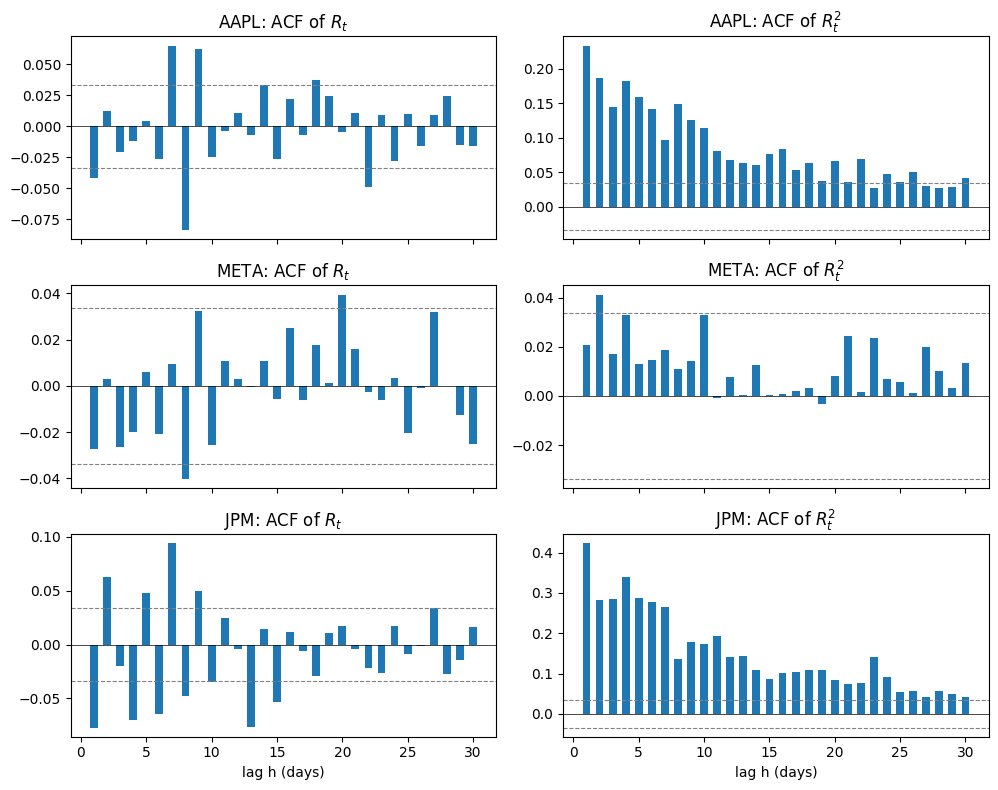

Ljung-Box, H = 10, 5% critical value = 18.31
      Q_LB (R_t)   p (R_t) reject (R_t)  Q_LB (R_t^2) p (R_t^2)  \
AAPL       64.43  < 0.0001          yes        849.29  < 0.0001   
META       19.58    0.0335          yes         19.10    0.0390   
JPM       124.29  < 0.0001          yes       2607.49  < 0.0001   

     reject (R_t^2)  rho1 (R_t)  max|rho| (R_t)  rho1 (R_t^2)  
AAPL            yes      -0.042           0.084         0.234  
META            yes      -0.028           0.040         0.021  
JPM             yes      -0.077           0.094         0.423  


In [5]:
# Question 1(b)

NLAGS = 30

def acf(x, nlags):
    """Sample autocorrelations rho_hat(1), ..., rho_hat(nlags)."""
    x = np.asarray(x, dtype=float)
    n = len(x)
    xc = x - x.mean()                      # centered series
    denom = xc @ xc                        # sum of squares, same for every lag
    return np.array([(xc[h:] @ xc[:n - h]) / denom for h in range(1, nlags + 1)])

# 1. ACF figure 
lags = np.arange(1, NLAGS + 1)
band = 1.96 / np.sqrt(len(returns))        # 95% band under i.i.d.

fig, axes = plt.subplots(len(TICKERS), 2, figsize=(10, 8), sharex=True)
for i, tic in enumerate(TICKERS):
    r = returns[tic].to_numpy()
    for j, (series, name) in enumerate([(r, "$R_t$"), (r**2, "$R_t^2$")]):
        ax = axes[i, j]
        ax.bar(lags, acf(series, NLAGS), width=0.6)
        ax.axhline(band, ls="--", color="grey", lw=0.8)
        ax.axhline(-band, ls="--", color="grey", lw=0.8)
        ax.axhline(0, color="black", lw=0.5)
        ax.set_title(f"{tic}: ACF of {name}")
for ax in axes[-1]:
    ax.set_xlabel("lag h (days)")
    a, a2 = acf(r, NLAGS), acf(r**2, NLAGS)

plt.tight_layout()
fig.savefig(OUT_DIR / "q1b_acf.png", dpi=150)
plt.show()

# 2. Ljung-Box tests
lb_rows = []
for tic in TICKERS:
    r = returns[tic]
    for series, name in [(r, "R_t"), (r**2, "R_t^2")]:
        res = acorr_ljungbox(series, lags=[LB_LAGS], return_df=True)
        lb_rows.append({
            "stock": tic,
            "series": name,
            "Q_LB": res["lb_stat"].iloc[0],
            "p_value": res["lb_pvalue"].iloc[0],
        })

# 3. Clean table
lb_df = pd.DataFrame(lb_rows)
crit = stats.chi2.ppf(0.95, LB_LAGS)

def fmt_p(p):
    return "< 0.0001" if p < 1e-4 else f"{p:.4f}"

clean = pd.DataFrame(index=TICKERS)
for name in ["R_t", "R_t^2"]:
    sub = lb_df[lb_df["series"] == name].set_index("stock")
    clean[f"Q_LB ({name})"] = sub["Q_LB"].round(2)
    clean[f"p ({name})"] = sub["p_value"].map(fmt_p)
    clean[f"reject ({name})"] = (sub["Q_LB"] > crit).map({True: "yes", False: "no"})
# ACF summary, added to the same table
for tic in TICKERS:
    r = returns[tic].to_numpy()
    a, a2 = acf(r, NLAGS), acf(r**2, NLAGS)
    clean.loc[tic, "rho1 (R_t)"] = round(a[0], 3)
    clean.loc[tic, "max|rho| (R_t)"] = round(np.abs(a).max(), 3)
    clean.loc[tic, "rho1 (R_t^2)"] = round(a2[0], 3)


print(f"Ljung-Box, H = {LB_LAGS}, 5% critical value = {crit:.2f}")
print(clean)
clean.to_csv(OUT_DIR / "q1b_ljungbox.csv")

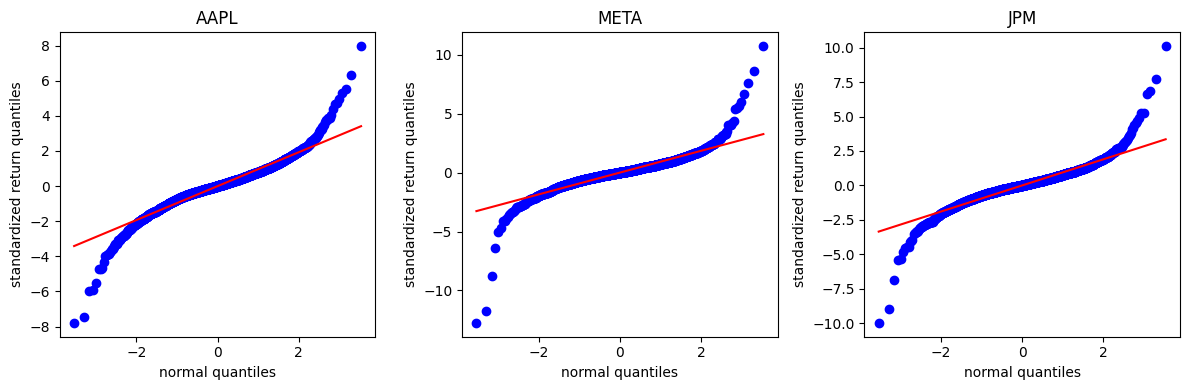

chi2_2 critical value at 5%: 5.99
       skewness  kurtosis       JB   p_value
stock                                       
AAPL     -0.225      9.81   6590.6  < 0.0001
META     -0.497     27.39  84216.1  < 0.0001
JPM      -0.084     15.94  23655.8  < 0.0001


In [6]:
# Question 1(c)
fig, axes = plt.subplots(1, len(TICKERS), figsize=(12, 4))
jb_rows = []
for ax, tic in zip(axes, TICKERS):
    r = returns[tic].to_numpy()
    n = len(r)

    # QQ-plot against the normal distribution
    z = (r - r.mean()) / r.std(ddof=1)            # standardized returns
    stats.probplot(z, dist="norm", plot=ax)
    ax.set_title(tic)                             # probplot sets its own title
    ax.set_xlabel("normal quantiles")
    ax.set_ylabel("standardized return quantiles")

    # Jarque-Bera test
    b = stats.skew(r)
    kappa = stats.kurtosis(r, fisher=False)                  # normal = 3
    JB = n /6 *(b**2 + 1/4*(kappa -3)**2)
    jb_rows.append({"stock": tic, "skewness": b, "kurtosis": kappa,
                    "JB": JB, "p_value": stats.chi2.sf(JB, 2)})

plt.tight_layout()
fig.savefig(OUT_DIR / "q1c_qq.png", dpi=150)
plt.show()

jb_table = pd.DataFrame(jb_rows).set_index("stock")
jb_table["skewness"] = jb_table["skewness"].round(3)
jb_table["kurtosis"] = jb_table["kurtosis"].round(2)
jb_table["JB"] = jb_table["JB"].round(1)
jb_table["p_value"] = jb_table["p_value"].map(fmt_p)

print("chi2_2 critical value at 5%:", round(stats.chi2.ppf(0.95, 2), 2))
print(jb_table)
jb_table.to_csv(OUT_DIR / "q1c_jarquebera.csv")

## Question 2 -- Single-window VaR and ES estimates

For each stock, use the first `WINDOW` losses as the single estimation window for (a)-(d).

In [18]:
# Question 2

def var_es_hs(x, alpha):
    """Historical-simulation VaR and ES of the losses x at level alpha."""
    L = np.sort(np.asarray(x, dtype=float))[::-1]       # decreasing order
    W = len(L)
    k = int(np.floor(W * (1 - alpha)))
    var = L[k]
    es = (L[:k].sum() + (W * (1 - alpha) - k) * L[k]) / (W * (1 - alpha))
    return var, es


def var_es_gauss(x, alpha):
    """Gaussian VaR and ES, (mu, sigma) estimated by sample moments."""
    x = np.asarray(x, dtype=float)
    mu, sigma = x.mean(), x.std(ddof=1)
    z = stats.norm.ppf(alpha)
    return mu + sigma * z, mu + sigma * stats.norm.pdf(z) / (1 - alpha)


def var_es_student(params, alpha):
    """Student-t VaR and ES from fitted parameters (nu, mu, sigma)."""
    nu, mu, sigma = params
    q = stats.t.ppf(alpha, nu)
    var = mu + sigma * q
    es = mu + sigma * stats.t.pdf(q, nu) / (1 - alpha) * (nu + q**2) / (nu - 1)
    return var, es

In [20]:
q2_rows = []
q2_nu = {}
for tic in TICKERS:
    x = window_loss[tic].to_numpy()
    params = fit_student(x)
    q2_nu[tic] = params[0]
    for alpha in ALPHAS:
        for method, (v, e) in [("HS", var_es_hs(x, alpha)),
                               ("Gaussian", var_es_gauss(x, alpha)),
                               ("Student-t", var_es_student(params, alpha))]:
            q2_rows.append({"stock": tic, "alpha": alpha, "method": method, "VaR": v, "ES": e})
print(pd.Series(q2_nu).round(2))
print(pd.DataFrame(q2_rows).round(5))

AAPL    4.13
META    4.68
JPM     6.48
dtype: float64
   stock  alpha     method      VaR       ES
0   AAPL  0.975         HS  0.02901  0.04974
1   AAPL  0.975   Gaussian  0.03068  0.03673
2   AAPL  0.975  Student-t  0.02947  0.04249
3   AAPL  0.990         HS  0.03888  0.07389
4   AAPL  0.990   Gaussian  0.03655  0.04198
5   AAPL  0.990  Student-t  0.03993  0.05555
6   META  0.975         HS  0.04235  0.05596
7   META  0.975   Gaussian  0.04720  0.05669
8   META  0.975  Student-t  0.04541  0.06351
9   META  0.990         HS  0.05348  0.06530
10  META  0.990   Gaussian  0.05640  0.06492
11  META  0.990  Student-t  0.06034  0.08137
12   JPM  0.975         HS  0.02383  0.02921
13   JPM  0.975   Gaussian  0.02198  0.02637
14   JPM  0.975  Student-t  0.02244  0.02987
15   JPM  0.990         HS  0.02778  0.03536
16   JPM  0.990   Gaussian  0.02623  0.03017
17   JPM  0.990  Student-t  0.02889  0.03694


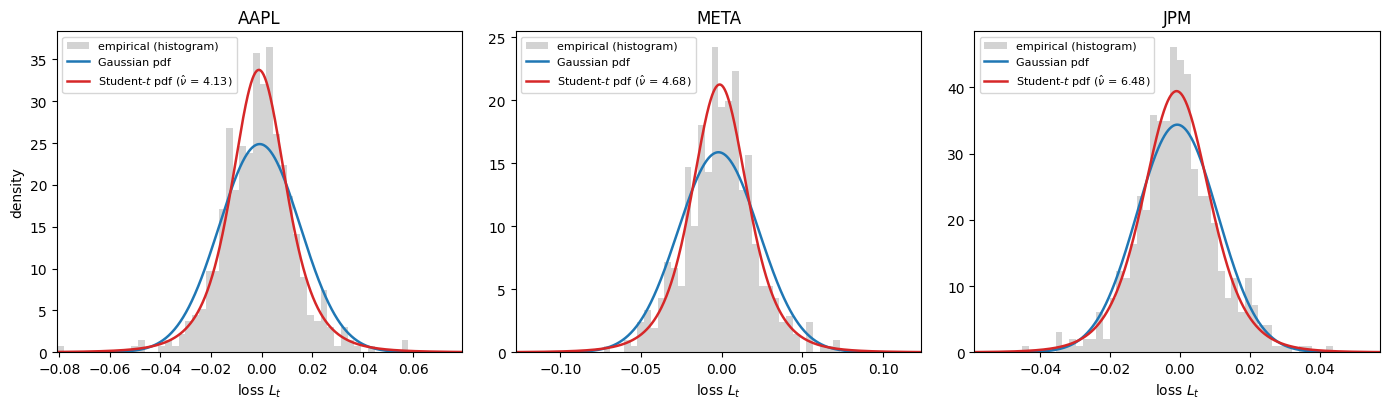

In [21]:
# Question 2(d)
fig, axes = plt.subplots(1, len(TICKERS), figsize=(14, 4.2))
for ax, tic in zip(axes, TICKERS):
    Ld = window_loss[tic].to_numpy()
    mu_g, sd_g = Ld.mean(), Ld.std(ddof=1)           # same estimates as in (b)
    nu_t, mu_t, sc_t = fit_student(Ld)               # same estimates as in (c)

    lo, hi = mu_g - 5 * sd_g, mu_g + 5 * sd_g
    grid = np.linspace(lo, hi, 1000)

    ax.hist(Ld, bins=np.linspace(lo, hi, 61), density=True, color="lightgrey", label="empirical (histogram)")
    ax.plot(grid, stats.norm.pdf(grid, mu_g, sd_g), color="tab:blue", lw=1.8, label="Gaussian pdf")
    ax.plot(grid, stats.t.pdf(grid, nu_t, mu_t, sc_t), color="tab:red", lw=1.8,
            label=f"Student-$t$ pdf ($\\hat\\nu$ = {nu_t:.2f})")
    ax.set_xlim(lo, hi)
    ax.set_title(tic)
    ax.set_xlabel("loss $L_t$")
    ax.legend(fontsize=8, loc="upper left")

axes[0].set_ylabel("density")
plt.tight_layout()
fig.savefig(OUT_DIR / "q2d_densities.png", dpi=150, bbox_inches="tight")
plt.show()

## Question 3 -- Backtesting

Forecast every day of the evaluation period `losses.iloc[EVAL_START:]`, each model estimated on the
`WINDOW` days before the forecast day. Historical simulation, Gaussian and Student-$t$ are recomputed
every day. Write the Kupiec, Christoffersen, Acerbi-Szekely, Fissler-Ziegel, pinball-loss and
Diebold-Mariano functions yourself, from the course slides (Kupiec, Christoffersen) and Appendix A of
the project statement (the others); they are
reused unchanged in Questions 4 and 5.

The combined VaR backtest table collects the VaR backtests of Questions 3-5: append one row per
stock, method and level to `backtest_rows` as you go. The ES backtest table ($\alpha=0.975$) collects
the Acerbi-Szekely and Fissler-Ziegel results of Questions 3 and 4 in `es_rows`.

In [26]:
# Question 3
eval_loss = losses.iloc[EVAL_START:]        # one column per stock, 2888 forecast days
backtest_rows = []                          # dicts: stock, method, alpha, x, expected, hit, p_uc, p_ind, p_cc, pinball_bp
es_rows = []                                # dicts: stock, method, Z, p_Z, FZ


METHODS = ["HS", "Gaussian", "Student-t"]
n_eval = len(losses) - EVAL_START                     # 2888

var_fc = {(tic, m, alpha): np.empty(n_eval) for tic in TICKERS for m in METHODS for alpha in ALPHAS}
es_fc  = {(tic, m, alpha): np.empty(n_eval) for tic in TICKERS for m in METHODS for alpha in ALPHAS}

for tic in TICKERS:
    L = losses[tic].to_numpy()
    for i, t in enumerate(range(EVAL_START, - len(L))):
        x = L[t - WINDOW: t]
        params = fit_student(x)
        for alpha in ALPHAS:
            var_fc[(tic, "HS", alpha)][i], es_fc[(tic, "HS", alpha)][i] = var_es_hs(x, alpha)
            var_fc[(tic, "Gaussian", alpha)][i], es_fc[(tic, "Gaussian", alpha)][i] = var_es_gauss(x, alpha)
            var_fc[(tic, "Student-t", alpha)][i], es_fc[(tic, "Student-t", alpha)][i] = var_es_student(params, alpha)
    print(tic, "done")

print(var_fc[("AAPL", "Student-t", 0.99)][0])    # should equal the Q2 value, 0.0399




AAPL done
META done
JPM done
0.0


## Question 4 -- AR-GARCH conditional VaR and ES

(a) Mean model, full sample: fit AR($p$), $p=0,\dots,3$, with constant variance on the same
observations, e.g. `ARX(y, lags=p, hold_back=3)` from `arch.univariate`; pick $p$ by BIC (also report
AIC); Ljung-Box on the residuals (`model_df=p`) and on their squares.
(b) Fit `arch_model(y, mean="AR", lags=p, vol="GARCH", p=1, q=1, dist=..., hold_back=3)` on the full
sample with `dist="normal"` and `dist="t"` (use `mean="Constant"` if $p=0$); Ljung-Box on the
standardized residuals of the Gaussian fit (`model_df=p`) and their squares (`model_df=2`).
(c) Re-estimate both inside the rolling scheme every `REFIT` days with the same $p$. Between refits,
keep the parameters fixed but advance $\hat\mu_t$ and $\hat\sigma_t$ daily with the realized
returns (for example with `arch_model(...).fix(params)` on the data up to the forecast day). Fit on
returns in percent (`100 * R`) to avoid `arch` convergence warnings, and convert the forecasts back.
(d) Backtest both and add them to the two tables.

In [12]:
# Question 4
from arch import arch_model


ModuleNotFoundError: No module named 'arch'

## Question 5 -- Quantile regression

Same evaluation period, window and refit days as Question 4. One model per stock and level, VaR only;
the two features are built by `make_features` below, both using information up to $t-1$; the target
is the loss $L_t$. Rows with an undefined feature (the first 20 days) are dropped from the training
window. Linear quantile regression, e.g.
`sm.QuantReg(y, sm.add_constant(X)).fit(q=alpha, max_iter=5000)`.

In [ ]:
# Question 5
import statsmodels.api as sm


def make_features(ret: pd.Series) -> pd.DataFrame:
    """Features x_{t-1} for the forecast of day t: row t uses information up to t-1 only."""
    feat = pd.DataFrame(index=ret.index)
    feat["absR_lag1"] = ret.shift(1).abs()
    feat["sigma20"] = ret.shift(1).rolling(20).std(ddof=1)
    return feat


# After (a) and (b): the combined VaR backtest table, one table per level
# backtest_table = pd.DataFrame(backtest_rows).set_index(["alpha", "stock", "method"]).sort_index()


## Question 6 -- Extreme value theory

One static fit on each stock's full-sample log-loss series, with threshold $u$ the empirical 95%
quantile. `scipy.stats.genpareto.fit(excesses, floc=0)` may be used for the GPD maximum-likelihood
step.

In [ ]:
# Question 6
from scipy.stats import genpareto
full_loss = losses                          # one column per stock
